# Data Science w Pythonie — Zajęcia 5

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_5.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_5/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Feature engineering — cechy, które mówią więcej

Do tej pory brałeś kolumny takie, jakie przyszły z systemu, i najwyżej je
czyściłeś. Tymczasem model widzi tylko liczby w kolumnach. Nie wie, że opłata
199 zł przy jednej wizycie w miesiącu to pieniądze wyrzucone w błoto, a klient
z 10 wizytami za te same 199 zł robi świetny interes. Ty to wiesz — i możesz mu
to powiedzieć, dopisując nową kolumnę.

To jest **feature engineering** (inżynieria cech): budowanie z danych, które już
masz, nowych cech, które lepiej opisują problem. Ilorazy, progi, kategorie
zamienione na liczby, podsumowania z innych tabel. W projektach na danych
tabelarycznych to zwykle daje więcej niż zamiana modelu na „mądrzejszy" — i za
godzinę na Uczeniu głębokim sprawdzisz to na własnych liczbach.

Po dzisiejszych zajęciach będziesz w stanie:

- wyjaśnić, czym jest cecha i feature engineering,
- sprawdzić, czy cecha mówi coś o zmiennej celu — `corrwith` i odsetek
  w przedziałach,
- budować cechy z liczb: ilorazy i flagi,
- zamieniać kategorie na liczby — mapowaniem `map` (gdy jest porządek)
  i kodowaniem one-hot `get_dummies` (gdy go nie ma),
- budować cechy z tabeli zdarzeń i z dat,
- rozpoznać **wyciek danych** — cechę, której nie znałbyś w chwili decyzji.

> ℹ️ **Gdzie jesteśmy**
>
> W workflow projektu z pierwszych zajęć to ostatni krok przygotowania
> danych — tuż przed modelem. Dane są już czyste (zajęcia 2), obejrzane
> (zajęcia 3) i zebrane w jedną tabelę (zajęcia 4). Teraz robimy z nich
> tabelę, z której model nauczy się jak najwięcej. Ćwiczymy na siłowni,
> w zadaniu wracamy do MeritoBanku — a za godzinę na
> [Uczeniu głębokim](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_5/) Twoje cechy trafią do
> pierwszej sieci neuronowej.


## Plan na dziś

| Blok | Czas |
|---|---|
| Czym jest cecha i jak sprawdzić, czy coś mówi | 5 min |
| Cechy z liczb — ilorazy i flagi | 10 min |
| Kategorie na liczby — `map` i one-hot | 10 min |
| Cechy z tabeli zdarzeń i z dat | 10 min |
| Wyciek danych i gotowa tabela cech | 7 min |
| Ściągawka | 3 min |
| **Zadanie 5** | **45 min** |


## Cecha i jak ją ocenić

### Dane, na których pracujemy

Znowu siłownia — wyczyszczona wersja z zajęć 3 i 4:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)
df.head(3)

,klient_id,wiek,miasto,typ_karnetu,oplata_mies,staz_mies,wizyty_mies,zgloszenia,zrezygnowal
0,K1342,45,Gdańsk,Basic,99.0,20,1.2,0,1
1,K0802,34,Poznań,Standard,119.0,17,7.6,1,0
2,K0240,34,Warszawa,Basic,99.0,5,5.1,1,0


**Cecha** (*feature*) to każda kolumna, na podstawie której model ma coś
przewidzieć — tu: wiek, opłata, staż, wizyty, zgłoszenia, miasto, typ karnetu.
**Zmienna celu** to to, co przewidujemy — `zrezygnowal`. Znasz to z pierwszych
zajęć z Uczenia głębokiego.

### Czy cecha coś mówi?

Zanim zaczniemy dopisywać kolumny, potrzebujemy miary, czy nowa kolumna jest
lepsza od starych. Najprostsza to korelacja z zajęć 3 — tym razem liczona
między każdą cechą a zmienną celu. Robi to jedna metoda, `corrwith`:

In [2]:
liczbowe = ["wiek", "oplata_mies", "staz_mies", "wizyty_mies", "zgloszenia"]
df[liczbowe].corrwith(df["zrezygnowal"]).round(3)

wiek          -0.045
oplata_mies    0.132
staz_mies     -0.228
wizyty_mies   -0.227
zgloszenia     0.160
dtype: float64

Czytasz to tak samo jak mapę ciepła: **znak** to kierunek (ujemna — im więcej,
tym rzadziej klient odchodzi), **wartość bezwzględna** to siła. Najmocniejsze
są dziś staż i wizyty, ok. 0.23. To jest poprzeczka — nowa cecha jest warta
uwagi, jeśli ją przeskoczy.

> 📝 **Korelacja to pierwsze sito, nie wyrok**
>
> Korelacja widzi tylko zależności typu „im więcej, tym więcej". Cecha
> o korelacji bliskiej zera może być przydatna, jeśli ryzyko rośnie np. tylko
> powyżej jakiegoś progu. Dlatego do korelacji zawsze warto dołożyć odsetek
> w przedziałach — jak za chwilę.


## Cechy z liczb

### Iloraz — ile kosztuje jedna wizyta

Opłata sama w sobie mówi niewiele: 199 zł to dużo czy mało? Zależy, ile razy
klient przychodzi. Zróbmy cechę, która łączy obie informacje — **koszt jednej
wizyty**:

In [3]:
df["koszt_wizyty"] = df["oplata_mies"] / df["wizyty_mies"]
df[["oplata_mies", "wizyty_mies", "koszt_wizyty"]].head(3).round(1)

,oplata_mies,wizyty_mies,koszt_wizyty
0,99.0,1.2,82.5
1,119.0,7.6,15.7
2,99.0,5.1,19.4


Klient z pierwszego wiersza przychodzi nieco ponad raz w miesiącu, więc za
jedno wejście płaci 82.50 zł — prawie tyle, co inni za cały miesiąc. Czy nowa
cecha przeskakuje poprzeczkę?

In [4]:
df[["oplata_mies", "wizyty_mies", "koszt_wizyty"]].corrwith(df["zrezygnowal"]).round(3)

oplata_mies     0.132
wizyty_mies    -0.227
koszt_wizyty    0.296
dtype: float64

Przeskakuje i to wyraźnie: 0.30 wobec 0.13 i 0.23 dla kolumn, z których
powstała. Zobaczmy to w przedziałach:

In [5]:
przedzialy = pd.cut(df["koszt_wizyty"], bins=[0, 15, 25, 50, 100, 500])
df.groupby(przedzialy, observed=True)["zrezygnowal"].agg(["count", "mean"]).round(3)

,count,mean
koszt_wizyty,,
"(0, 15]",444,0.122
"(15, 25]",413,0.145
"(25, 50]",433,0.305
"(50, 100]",147,0.497
"(100, 500]",47,0.638


Text(0, 0.5, 'odsetek klientów, którzy zrezygnowali')

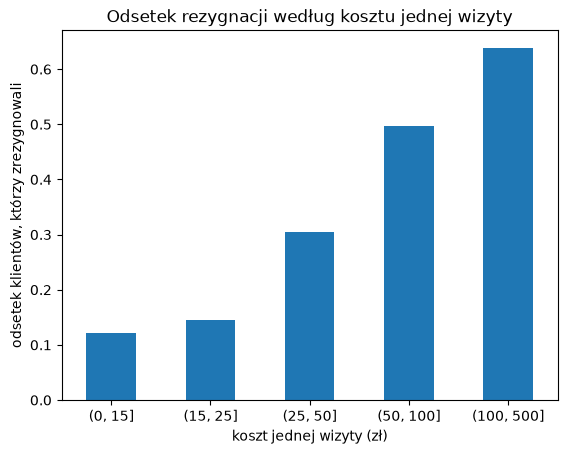

In [6]:
df.groupby(przedzialy, observed=True)["zrezygnowal"].mean().plot(
    kind="bar", title="Odsetek rezygnacji według kosztu jednej wizyty")
plt.xticks(rotation=0)
plt.xlabel("koszt jednej wizyty (zł)")
plt.ylabel("odsetek klientów, którzy zrezygnowali")

Kto płaci za wizytę do 25 zł, odchodzi w 12–15% przypadków. Kto płaci ponad
100 zł — prawie w dwóch przypadkach na trzy. To jest informacja, której nie było
w żadnej pojedynczej kolumnie: model, który dostaje osobno opłatę i wizyty,
musiałby sam „wymyślić" dzielenie. Prosty model tego nie umie, a sieć
neuronowa — tylko jeśli ma dość danych.

> ⚠️ **Dzielenie przez zero**
>
> Klient z zerową liczbą wizyt dostałby koszt wizyty `inf` (nieskończoność)
> i popsułby każdą średnią. W naszych danych najmniejsza wartość to 0.4, ale
> zawsze to sprawdzaj: `(df["wizyty_mies"] == 0).sum()`. Jeśli zera są,
> zdecyduj, co znaczą — np. `df["wizyty_mies"].clip(lower=0.5)` traktuje
> „zero wizyt" jak „pół wizyty", więc koszt wychodzi wysoki, ale skończony.

### Flaga — tak albo nie

Czasem ważniejsze od dokładnej wartości jest to, czy przekroczyła próg. Na
zajęciach 4 wyszło, że w pierwszym półroczu odchodzi prawie 40% klientów.
Zróbmy z tego cechę — **flagę** 0/1:

In [7]:
df["nowy_klient"] = (df["staz_mies"] <= 6).astype(int)
df.groupby("nowy_klient")["zrezygnowal"].agg(["count", "mean"]).round(3)

,count,mean
nowy_klient,,
0,1343,0.218
1,141,0.397


Porównanie `df["staz_mies"] <= 6` daje serię `True`/`False`, a `astype(int)`
zamienia ją na 1/0 — tak lubią modele. Flaga przydaje się wtedy, gdy ryzyko
**skacze** na progu, a nie zmienia się równo. Model liczący ważoną sumę (jak
regresja logistyczna) sam takiego skoku nie zapisze — ze stażu w miesiącach
wyjdzie mu tylko „im dłużej, tym lepiej, zawsze w tym samym tempie".

> 📝 **A logarytm?**
>
> Kwoty — dochody, ceny domów, kwoty kredytów — mają zwykle długi prawy ogon:
> większość klientów zarabia kilka tysięcy, kilku zarabia kilkadziesiąt.
> Częstą cechą jest wtedy logarytm, `np.log(df["dochod"])`, który ten ogon
> „ściska". Na siłowni nie ma takich kolumn, więc dziś go tylko odnotowujemy.


## Kategorie na liczby

Regresja logistyczna i sieć neuronowa liczą ważoną sumę cech. Nie da się
pomnożyć „Warszawy" przez wagę 0.3. Kolumny tekstowe trzeba więc zamienić na
liczby — i sposób zależy od tego, czy kategorie mają **porządek**.

### Kategorie z porządkiem — `map`

Karnety mają naturalną kolejność: Basic < Standard < Premium. Zapisujemy ją
słownikiem:

In [8]:
df["karnet_poziom"] = df["typ_karnetu"].map({"Basic": 1, "Standard": 2, "Premium": 3})
df[["typ_karnetu", "karnet_poziom"]].drop_duplicates()

,typ_karnetu,karnet_poziom
0,Basic,1
1,Standard,2
27,Premium,3


Jeśli po `map` pojawią się braki (`df["karnet_poziom"].isna().sum()`), to
w danych jest wartość spoza słownika — np. `"premium "` ze spacją. Wracasz
wtedy do ujednolicania tekstu z zajęć 2.

### Kategorie bez porządku — one-hot

Z miastami tak się nie da. Gdyby Warszawa była 1, a Kraków 2, model uznałby,
że Kraków to „dwa razy Warszawa", a Gdańsk (3) leży „dalej" od Warszawy niż
Kraków. Bzdura. Zamiast tego każde miasto dostaje **własną kolumnę 0/1** — to
jest **kodowanie one-hot** (*one-hot encoding*, „jedna gorąca"):

In [9]:
miasta = pd.get_dummies(df["miasto"], prefix="miasto", dtype=int)
miasta.head(3)

,miasto_Gdańsk,miasto_Kraków,miasto_Poznań,miasto_Warszawa,miasto_Wrocław
0,1,0,0,0,0
1,0,0,1,0,0
2,0,0,0,1,0


W każdym wierszu jest dokładnie jedna jedynka — w kolumnie miasta klienta.
`prefix` dokleja przedrostek do nazw kolumn, a `dtype=int` daje zera
i jedynki zamiast `False`/`True`. Nowe kolumny doklejamy obok tabeli —
`pd.concat` z `axis=1` (z zajęć 4 znasz go w wersji „jedna pod drugą"):

In [10]:
print(df.shape)
df = pd.concat([df, miasta], axis=1)
print(df.shape)

(1484, 12)
(1484, 17)


Pięć miast — pięć nowych kolumn. Oryginalną kolumnę `miasto` zostawiamy, żeby
dało się po niej grupować — do modelu po prostu jej nie weźmiemy.

> ⚠️ **One-hot nie na wszystko**
>
> - **Kategorie o tysiącach wartości** (identyfikator klienta, kod pocztowy)
>   dałyby tysiące kolumn, z których każda opisuje kilka osób. `klient_id`
>   w ogóle nie jest cechą — to tylko etykieta wiersza.
> - **Nowe kategorie.** Pamiętasz Łódź z zajęć 4? Model nauczony na pięciu
>   miastach nie ma kolumny `miasto_Łódź`. Gdy pojawi się pierwszy klient
>   z Łodzi, dostanie same zera — model potraktuje go jak „miasto przeciętne".


## Cechy z tabeli zdarzeń

### Nie tylko „ile", ale „jakie"

Kolumna `zgloszenia` mówi, ile zgłoszeń złożył klient. Na zajęciach 4 wyszło
jednak, że ważniejsze jest, **jakie**: na sprzęt narzekają ci, którzy chodzą,
a na obsługę i płatności — ci, którzy zaraz odejdą. Zróbmy z tego cechy.
Najpierw liczba zgłoszeń każdej kategorii dla każdego klienta — `groupby` po
dwóch kolumnach i `unstack`, jak na zajęciach 4:

In [11]:
URL_ZGL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/dane/zgloszenia_2026.csv"
zgl = pd.read_csv(URL_ZGL)

kategorie = zgl.groupby(["klient_id", "kategoria"]).size().unstack(fill_value=0)
kategorie = kategorie.add_prefix("zgl_")
kategorie.head(3)

kategoria,zgl_czystość,zgl_obsługa,zgl_płatności,zgl_sprzęt,zgl_tłok
klient_id,,,,,
K0005,1,0,0,0,1
K0006,1,0,0,0,0
K0007,0,0,1,0,1


`unstack(fill_value=0)` od razu wpisuje zero tam, gdzie klient nie miał
zgłoszenia danej kategorii, a `add_prefix` dokleja przedrostek do nazw kolumn.
Teraz łączymy z klientami — `left`, a klientom bez żadnego zgłoszenia
wpisujemy zera:

In [12]:
kolumny_zgl = list(kategorie.columns)
df = df.merge(kategorie.reset_index(), on="klient_id", how="left")
df[kolumny_zgl] = df[kolumny_zgl].fillna(0).astype(int)
print(df.shape)

df[kolumny_zgl + ["zgloszenia"]].corrwith(df["zrezygnowal"]).round(3)

(1484, 22)


zgl_czystość     0.007
zgl_obsługa      0.188
zgl_płatności    0.188
zgl_sprzęt      -0.044
zgl_tłok         0.068
zgloszenia       0.160
dtype: float64

Zgłoszenia o obsłudze i płatnościach mają z rezygnacją korelację 0.19 każde
— więcej niż wszystkie zgłoszenia razem (0.16). Zgłoszenia o sprzęcie mają
nawet znak ujemny. Złóżmy obie „złe" kategorie w jedną cechę:

In [13]:
df["zgl_powazne"] = df["zgl_obsługa"] + df["zgl_płatności"]
print("korelacja:", round(df["zgl_powazne"].corr(df["zrezygnowal"]), 3))

df.groupby(df["zgl_powazne"].clip(upper=2))["zrezygnowal"].agg(["count", "mean"]).round(3)

korelacja: 0.258


,count,mean
zgl_powazne,,
0,1192,0.185
1,247,0.401
2,45,0.644


Korelacja 0.26 — prawie dwa razy więcej niż sama liczba zgłoszeń.
`clip(upper=2)` zamienia wszystko powyżej 2 na 2, więc ostatni wiersz czytaj
„2 i więcej". Klient bez poważnych zgłoszeń odchodzi w 19% przypadków,
z dwoma — w 64%.

### Cechy z dat

Dziennik zgłoszeń ma też datę. Z daty da się wyciągnąć wiele cech — ale model
nie rozumie napisu `"2026-03-14"`. Najpierw zamieniamy go na datę
`pd.to_datetime` (zajęcia 2), a potem wyciągamy liczby:

| Chcę… | Kod |
|---|---|
| miesiąc (1–12) | `zgl["data"].dt.month` |
| dzień tygodnia (0 = poniedziałek) | `zgl["data"].dt.day_of_week` |
| czy weekend | `(zgl["data"].dt.day_of_week >= 5).astype(int)` |
| ile dni minęło | `(pd.Timestamp("2026-09-30") - zgl["data"]).dt.days` |

Dla nas najciekawsze jest ostatnie: **ile dni minęło od ostatniego zgłoszenia**
klienta. Dane kończą się 30 września 2026, więc to jest nasze „dziś":

In [14]:
zgl["data"] = pd.to_datetime(zgl["data"])
ostatnie = zgl.groupby("klient_id")["data"].max()
dni = (pd.Timestamp("2026-09-30") - ostatnie).dt.days

df = df.merge(dni.rename("dni_od_zgloszenia").reset_index(), on="klient_id", how="left")
print("brak zgłoszeń:", df["dni_od_zgloszenia"].isna().sum())

brak zgłoszeń: 663


Znowu 663 braki — klienci bez zgłoszeń. Tym razem **nie** uzupełniamy zerem:
zero dni znaczyłoby „zgłosił się dziś", czyli dokładnie odwrotnie. Uczciwiej
wpisać dużą liczbę — „dawno albo nigdy" — np. 365:

In [15]:
df["dni_od_zgloszenia"] = df["dni_od_zgloszenia"].fillna(365)

przedzialy_dni = pd.cut(df["dni_od_zgloszenia"], bins=[-1, 30, 90, 180, 300, 365])
df.groupby(przedzialy_dni, observed=True)["zrezygnowal"].agg(["count", "mean"]).round(3)

,count,mean
dni_od_zgloszenia,,
"(-1, 30]",135,0.333
"(30, 90]",212,0.307
"(90, 180]",260,0.238
"(180, 300]",214,0.252
"(300, 365]",663,0.186


Świeże zgłoszenie (ostatni miesiąc) to 33% rezygnacji, stare — 24–25%, brak
zgłoszeń — 19%. Efekt jest, ale słabszy niż przy kategoriach. Tak też bywa:
nie każda cecha, która brzmi sensownie, okazuje się mocna — dlatego każdą się
sprawdza.

> 💡 **Uzupełnianie braków po złączeniu**
>
> Za każdym razem zapytaj, co znaczy brak w **tej** kolumnie. Brak zgłoszeń
> w liczbie zgłoszeń to zero. Brak zgłoszeń w „dniach od zgłoszenia" to
> „bardzo dawno". Brak wieku w ankiecie to „nie wiemy" — i wtedy mediana.
> Ta sama metoda `fillna`, trzy różne decyzje.


## Wyciek danych

### Cecha za dobra, żeby była prawdziwa

Wyobraź sobie, że dział IT dorzuca do tabeli kolumnę `wizyty_pazdziernik` —
liczbę wizyt w październiku. Korelacja z rezygnacją wychodzi gigantyczna.
Nic dziwnego: kto zrezygnował we wrześniu, w październiku ma zero wizyt.
Model z taką cechą miałby świetne wyniki w notatniku i byłby **zupełnie
bezużyteczny** w praktyce — bo chcemy przewidzieć rezygnację, **zanim** się
zdarzy, a wtedy październikowych wizyt jeszcze nie ma.

To jest **wyciek danych** (*data leakage*): cecha, która zawiera informację
z przyszłości albo wprost z odpowiedzi. Na zajęciach 3 z Uczenia głębokiego
poznałeś wyciek przy skalowaniu. Ten jest groźniejszy, bo nie widać go w kodzie
— widać go dopiero, gdy zapytasz:

> **Czy znałbym tę wartość w chwili, w której model ma podjąć decyzję?**

| Cecha | Wyciek? | Dlaczego |
|---|---|---|
| liczba wizyt w ostatnim miesiącu przed decyzją | nie | znamy ją w chwili decyzji |
| wizyty w miesiącu **po** dacie, dla której przewidujemy | **tak** | to już przyszłość |
| powód rezygnacji z ankiety wyjściowej | **tak** | istnieje tylko dla tych, którzy odeszli |
| zgłoszenie „chcę anulować karnet" | **tak** | to właściwie sama odpowiedź |
| liczba zgłoszeń o płatnościach | raczej nie | ale warto spytać, czy nie powstają **przy** rezygnacji |

> ⛔ **Za dobre, żeby było prawdziwe**
>
> Jeśli jedna cecha ma z celem korelację 0.9 albo model nagle osiąga 99%
> accuracy — nie świętuj, tylko szukaj wycieku. W prawdziwych danych tak
> mocnych cech prawie nie ma. W zadaniu zobaczysz taki przypadek na własne
> oczy.

### Gotowa tabela cech

Na koniec zbieramy wszystko, co ma trafić do modelu. Tabela do modelu ma
cztery cechy: **jeden wiersz na klienta, same liczby, żadnych braków, żadnego
wycieku**:

In [16]:
cechy = (liczbowe
         + ["koszt_wizyty", "nowy_klient", "karnet_poziom", "zgl_powazne", "dni_od_zgloszenia"]
         + list(miasta.columns))

gotowe = df[cechy + ["zrezygnowal"]]
print(gotowe.shape, "| braków:", gotowe.isna().sum().sum())

gotowe.to_csv("silownia_cechy.csv", index=False)

(1484, 16) | braków: 0


Z 5 cech liczbowych zrobiło się 15. Tekstowe kolumny (`miasto`,
`typ_karnetu`) i `klient_id` zostały poza tabelą — ich informacja siedzi
w kolumnach liczbowych. Plik `silownia_cechy.csv` znajdziesz w Colabie
w panelu **Pliki** po lewej.

> 📝 **Więcej cech to nie zawsze lepiej**
>
> Każda cecha to dla modelu kolejna rzecz do nauczenia się, a danych mamy
> tyle samo. Cechy słabe albo powtarzające to samo (`zgloszenia`
> i `zgl_powazne`, `oplata_mies` i `karnet_poziom`) mogą modelowi bardziej
> przeszkodzić niż pomóc — zwłaszcza dużemu. Co z tego wychodzi w praktyce,
> zobaczysz za godzinę.


## Ściągawka

| Chcę… | Kod |
|---|---|
| korelacja każdej cechy z celem | `df[cechy].corrwith(df["cel"])` |
| korelacja jednej kolumny z celem | `df["kol"].corr(df["cel"])` |
| iloraz dwóch kolumn | `df["nowa"] = df["a"] / df["b"]` |
| sprawdzić zera przed dzieleniem | `(df["b"] == 0).sum()` |
| flaga 0/1 | `df["flaga"] = (df["kol"] > prog).astype(int)` |
| kategoria z porządkiem → liczba | `df["kol"].map({"niski": 1, "średni": 2, "wysoki": 3})` |
| kategoria bez porządku → one-hot | `pd.get_dummies(df["kol"], prefix="kol", dtype=int)` |
| dokleić kolumny obok | `pd.concat([df, nowe_kolumny], axis=1)` |
| zdarzenia → liczba w każdej kategorii | `zd.groupby(["id", "kategoria"]).size().unstack(fill_value=0)` |
| przedrostek w nazwach kolumn | `tabela.add_prefix("zgl_")` |
| obciąć wartości z góry | `df["kol"].clip(upper=2)` |
| tekst → data | `pd.to_datetime(df["data"])` |
| miesiąc / dzień tygodnia | `df["data"].dt.month`, `df["data"].dt.day_of_week` |
| ile dni minęło | `(pd.Timestamp("2026-09-30") - df["data"]).dt.days` |
| odsetek celu w przedziałach cechy | `df.groupby(pd.cut(df["kol"], bins=[...]), observed=True)["cel"].mean()` |
| zapisać tabelę do pliku | `df.to_csv("plik.csv", index=False)` |

## Zadanie 5

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/data_science_w_pythonie/zajecia_5/#zadanie-5-ile-z-pensji-idzie-na-rate-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.